# Diagnóstico automático de cartas dinamométricas con machine learning

**Problema real.** En un yacimiento con cientos de pozos con bombeo mecánico, los controladores de pozo (POC) y el
SCADA registran una carta dinamométrica por ciclo. Un ingeniero de producción revisa a ojo las cartas de fondo para
detectar fallas: golpe de fluido, interferencia de gas, fugas en las válvulas, varilla cortada o bomba golpeando abajo.
Es lento, depende de la experiencia de cada persona, y las fallas se detectan tarde.

**Objetivo.** Clasificar automáticamente cada carta de fondo en 7 clases y dar una probabilidad, para generar
alertas en el SCADA y priorizar las intervenciones.

**KPI de negocio.** Que las fallas críticas (varilla cortada, fugas) se detecten con exhaustividad (*recall*) alta.
Una falsa alarma cuesta una revisión; una falla no detectada cuesta producción diferida o una intervención mayor.

**Datos.** En un proyecto real vendrían del historiador del SCADA, con etiquetas puestas por ingenieros sobre cartas
revisadas. Aquí se generan con el simulador físico del repositorio (`bombeo_mecanico/`): ecuación de onda en la sarta,
bomba con válvulas y fallas. Esa es la limitación principal: **un modelo entrenado con datos sintéticos tiene que
validarse con cartas reales antes de usarse en operación**. Se discute al final.

In [1]:
import json, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.inspection import permutation_importance
BASE=Path('..'); DAT=BASE/'datos'; FIG=BASE/'figuras'; MOD=BASE/'modelo'
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'grid.alpha':.3,'font.size':9})
CLASES=['normal','golpe_de_fluido','interferencia_de_gas','fuga_valvula_viajera','fuga_valvula_fija','varilla_cortada','golpe_abajo']
NOMBRE={'normal':'Normal','golpe_de_fluido':'Golpe de fluido','interferencia_de_gas':'Interferencia de gas','fuga_valvula_viajera':'Fuga v. viajera',
        'fuga_valvula_fija':'Fuga v. fija','varilla_cortada':'Varilla cortada','golpe_abajo':'Golpe abajo'}
d=pd.read_csv(DAT/'dataset.csv'); o=pd.read_csv(DAT/'dataset_fuera_de_rango.csv')
print('Dataset base:',d.shape,' fuera de rango:',o.shape)
print(d.clase.value_counts().reindex(CLASES))

Dataset base: (2800, 144)  fuera de rango: (420, 144)
clase
normal                  400
golpe_de_fluido         400
interferencia_de_gas    400
fuga_valvula_viajera    400
fuga_valvula_fija       400
varilla_cortada         400
golpe_abajo             400
Name: count, dtype: int64


## 1. Exploración: cómo se ve cada falla
Cada fila tiene la carta de fondo remuestreada en 32 puntos de subida y 32 de bajada, a posiciones equiespaciadas.
También tiene la carta de superficie y los datos del pozo. Primero se miran los ejemplos de cada clase: la forma
de la carta tiene que ser la que describen los manuales de diagnóstico.

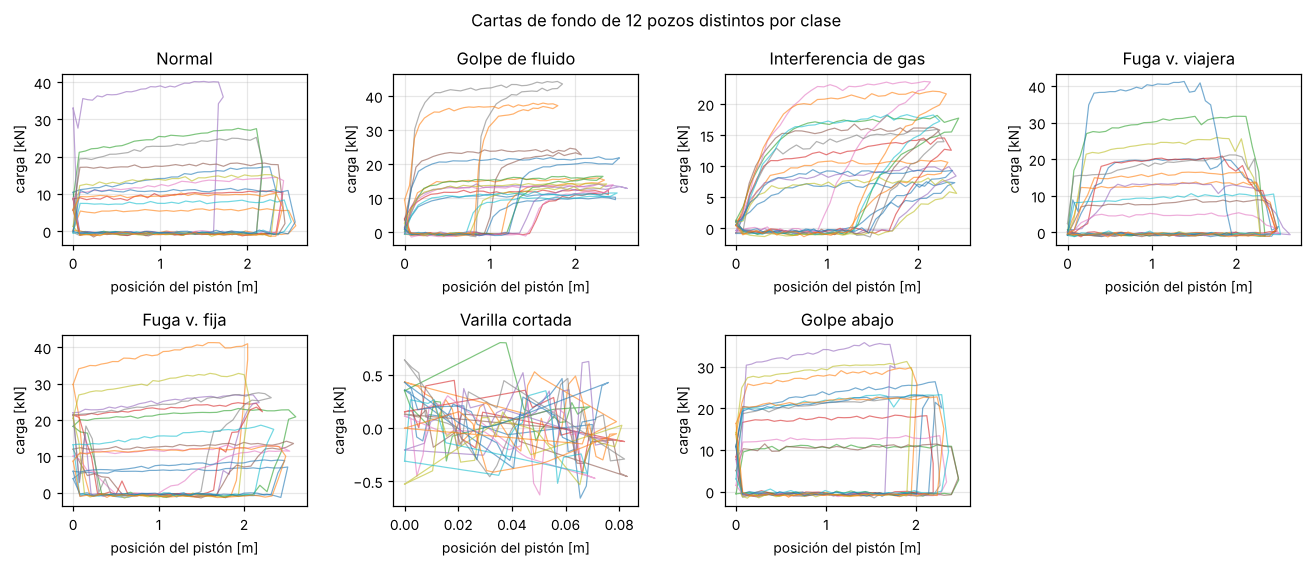

In [2]:
F=[f'fondo_{i}' for i in range(64)]; SUP=[f'sup_{i}' for i in range(64)]
x_up=np.linspace(0,1,32); x_dn=np.linspace(1,0,32)
fig,axs=plt.subplots(2,4,figsize=(12,5.2)); axs=axs.ravel()
for k,c in enumerate(CLASES):
    ax=axs[k]
    for _,r in d[d.clase==c].head(12).iterrows():
        v=r[F].values.astype(float); ax.plot(np.r_[x_up,x_dn]*r.carrera_bomba_m,v,lw=.8,alpha=.6)
    ax.set_title(NOMBRE[c]); ax.set_xlabel('posición del pistón [m]'); ax.set_ylabel('carga [kN]')
axs[-1].axis('off'); fig.suptitle('Cartas de fondo de 12 pozos distintos por clase'); fig.tight_layout(); fig.savefig(FIG/'01_cartas_por_clase.png'); plt.show()

## 2. Verificación de la fenomenología del dataset
Antes de entrenar se comprueba que cada etiqueta tenga la física que le corresponde. El generador ya descarta las
muestras dudosas (por ejemplo, un "golpe abajo" en el que el pistón no llegó a tocar el fondo). Aquí se verifica de nuevo:
- **Golpe de fluido** e **interferencia de gas**: la bomba no se llena (llenado < 0,9).
- **Fugas**: menos producción que un pozo sano de la misma capacidad.
- **Varilla cortada**: producción ≈ 0, y la carga de fondo no supera la fricción.
- **Golpe abajo**: carga de compresión (negativa) en el fondo de la carrera.

In [3]:
d['capacidad_bpd']=np.pi*(d.Dp_in*0.0254)**2/4*d.carrera_bomba_m*d.spm*1440/0.158987
d['prod_rel']=d.produccion_bpd/d.capacidad_bpd
resumen=d.groupby('clase').agg(llenado_medio=('llenado','mean'),prod_rel_media=('prod_rel','mean'),fondo_min_kN=('fondo_min_kN','median'),fondo_max_rel=('fondo_max_kN',lambda s:(s/d.loc[s.index,'Fo_kN']).median())).reindex(CLASES)
print(resumen.round(3))
assert resumen.loc['golpe_de_fluido','llenado_medio']<0.88 and resumen.loc['interferencia_de_gas','llenado_medio']<0.92
assert resumen.loc['varilla_cortada','prod_rel_media']<0.02 and resumen.loc['varilla_cortada','fondo_max_rel']<0.2
assert resumen.loc['golpe_abajo','fondo_min_kN']<-3
assert resumen.loc['fuga_valvula_viajera','prod_rel_media']<resumen.loc['normal','prod_rel_media']
assert resumen.loc['fuga_valvula_fija','prod_rel_media']<resumen.loc['normal','prod_rel_media']
print('\nChequeos de fenomenología del dataset: OK')
print(json.load(open(DAT/'resumen_base.json'))['stats'])

                      llenado_medio  prod_rel_media  fondo_min_kN  \
clase                                                               
normal                        1.000           0.972        -1.667   
golpe_de_fluido               0.584           0.549        -1.583   
interferencia_de_gas          0.419           0.521        -1.632   
fuga_valvula_viajera          1.000           0.485        -1.654   
fuga_valvula_fija             1.000           0.539        -1.657   
varilla_cortada               1.000           0.000        -1.126   
golpe_abajo                   1.000           0.972        -6.800   

                      fondo_max_rel  
clase                                
normal                        1.150  
golpe_de_fluido               1.077  
interferencia_de_gas          1.181  
fuga_valvula_viajera          1.178  
fuga_valvula_fija             1.161  
varilla_cortada               0.113  
golpe_abajo                   1.134  

Chequeos de fenomenología del datas

/tmp/ipykernel_4286/3396588607.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d['capacidad_bpd']=np.pi*(d.Dp_in*0.0254)**2/4*d.carrera_bomba_m*d.spm*1440/0.158987
/tmp/ipykernel_4286/3396588607.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d['prod_rel']=d.produccion_bpd/d.capacidad_bpd


## 3. Rasgos (features)
Se combinan tres tipos de información, todas disponibles en el campo:
1. **Forma normalizada** de la carta de fondo: 64 valores entre 0 y 1. Hace al modelo independiente del tamaño del pozo.
2. **Escala física**: carga máxima y mínima relativas a la carga de fluido teórica $F_o = (p_{desc}-p_{adm})A_p$ (sale de
   los datos del pozo y del nivel), y la relación entre la carrera del pistón y la de superficie.
3. **Rasgos de ingeniería**, los que mira un especialista: el área de la carta (≈ llenado), la posición donde la carga
   cae en la bajada (donde abre la viajera) y la posición donde sube en la subida (donde cierra la viajera).

Todas las fórmulas están replicadas tal cual en JavaScript para el despliegue (`clasificador.html`).

In [4]:
def rasgos(df,prefijo='fondo'):
    cols=[f'{prefijo}_{i}' for i in range(64)]; A=df[cols].values.astype(float)
    lo=A.min(1,keepdims=True); hi=A.max(1,keepdims=True); forma=(A-lo)/np.maximum(hi-lo,1.0)
    Fo=df.Fo_kN.values; up,dn=forma[:,:32],forma[:,32:]
    area=up.mean(1)-dn.mean(1)
    caida=np.array([1-(np.argmax(r<0.5) if (r<0.5).any() else 31)/31 for r in dn])   # posición (0-1) donde cae la carga al bajar
    subida=np.array([(np.argmax(r>0.5) if (r>0.5).any() else 31)/31 for r in up])     # posición donde se completa la carga al subir
    esc=np.c_[df[f'{prefijo}_max_kN']/Fo, df[f'{prefijo}_min_kN']/Fo, (df[f'{prefijo}_max_kN']-df[f'{prefijo}_min_kN'])/Fo, df.carrera_bomba_m/df.carrera_sup_m]
    ing=np.c_[area,caida,subida]
    nombres=[f'forma_{i}' for i in range(64)]+['max_rel','min_rel','rango_rel','rel_carreras','area','pos_caida','pos_subida']
    return np.c_[forma,esc,ing], nombres
X,NOMBRES=rasgos(d); y=d.clase.values; Xo,_=rasgos(o); yo=o.clase.values
Xtr,Xte,ytr,yte,itr,ite=train_test_split(X,y,np.arange(len(y)),test_size=0.25,stratify=y,random_state=0)
print('entrenamiento',Xtr.shape,' prueba',Xte.shape,' fuera de rango',Xo.shape)

entrenamiento (2100, 71)  prueba (700, 71)  fuera de rango (420, 71)


## 4. Línea base: reglas de ingeniero
Antes de usar ML hay que saber cuánto se logra con reglas simples, como las que tienen muchos POC:
- llenado bajo → golpe de fluido;
- carga máxima muy baja → varilla cortada;
- carga negativa grande → golpe abajo;
- si no, normal.

Si el modelo de ML no mejora claramente esta base, no vale la pena.

In [5]:
def reglas(Xs):
    out=[]
    for r in Xs:
        mx,mn,area=r[64],r[65],r[68]
        if mx<0.25: out.append('varilla_cortada')
        elif mn<-0.15: out.append('golpe_abajo')
        elif area<0.75: out.append('golpe_de_fluido')
        else: out.append('normal')
    return np.array(out)
p_reglas=reglas(Xte)
print(f'Reglas de ingeniero: exactitud {accuracy_score(yte,p_reglas):.3f}  F1 macro {f1_score(yte,p_reglas,average="macro"):.3f}')

Reglas de ingeniero: exactitud 0.499  F1 macro 0.378


## 5. Modelos de ML
- **Gradient boosting de histogramas** (`HistGradientBoostingClassifier`): un estándar industrial para datos tabulares,
  robusto e interpretable con importancia por permutación.
- **Red neuronal** (perceptrón multicapa, 64-32): aprende directamente de la forma.

Se entrenan con la carta de fondo. Más abajo se compara con un modelo entrenado con la carta de superficie.

In [6]:
hgb=HistGradientBoostingClassifier(max_iter=250,learning_rate=0.08,max_leaf_nodes=24,l2_regularization=1.0,random_state=0).fit(Xtr,ytr)
sc=StandardScaler().fit(Xtr); mlp=MLPClassifier((64,32),alpha=1e-3,max_iter=1500,random_state=0).fit(sc.transform(Xtr),ytr)
res=[]
for nom,pred,predo in [('Reglas de ingeniero',p_reglas,reglas(Xo)),('Gradient boosting',hgb.predict(Xte),hgb.predict(Xo)),('Red neuronal MLP',mlp.predict(sc.transform(Xte)),mlp.predict(sc.transform(Xo)))]:
    res.append({'modelo':nom,'exactitud prueba':accuracy_score(yte,pred),'F1 macro prueba':f1_score(yte,pred,average='macro'),'exactitud fuera de rango':accuracy_score(yo,predo)})
tabla=pd.DataFrame(res).set_index('modelo').round(3); print(tabla)
tabla.to_csv(MOD/'comparacion_modelos.csv')

                     exactitud prueba  F1 macro prueba  \
modelo                                                   
Reglas de ingeniero             0.499            0.378   
Gradient boosting               0.987            0.987   
Red neuronal MLP                0.990            0.990   

                     exactitud fuera de rango  
modelo                                         
Reglas de ingeniero                     0.467  
Gradient boosting                       0.967  
Red neuronal MLP                        0.962  


## 6. Matriz de confusión y métricas por clase
El gradient boosting generaliza mejor fuera del rango de entrenamiento, así que es el que se despliega. Se mira la
confusión en la prueba y en los pozos fuera de rango (más profundos, más rápidos, otros pistones y fluidos).

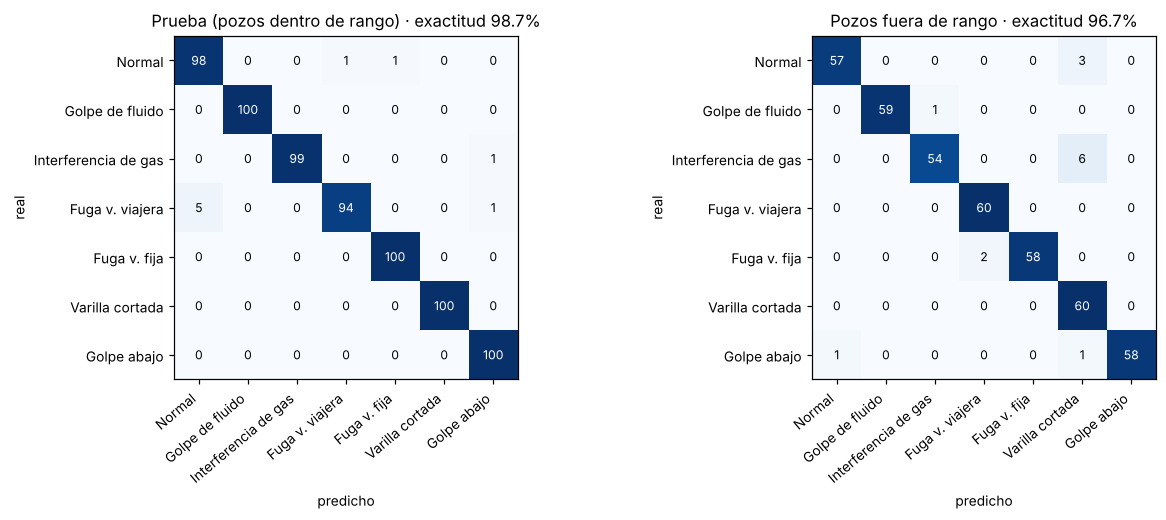

                      precision    recall  f1-score   support

              Normal      0.990     1.000     0.995       100
     Golpe de fluido      0.989     0.940     0.964       100
Interferencia de gas      0.980     1.000     0.990       100
     Fuga v. viajera      1.000     1.000     1.000       100
        Fuga v. fija      1.000     0.990     0.995       100
     Varilla cortada      0.951     0.980     0.966       100
         Golpe abajo      1.000     1.000     1.000       100

            accuracy                          0.987       700
           macro avg      0.987     0.987     0.987       700
        weighted avg      0.987     0.987     0.987       700



In [7]:
lab=[NOMBRE[c] for c in CLASES]
fig,axs=plt.subplots(1,2,figsize=(12,4.8))
for ax,(tit,yt,yp) in zip(axs,[('Prueba (pozos dentro de rango)',yte,hgb.predict(Xte)),('Pozos fuera de rango',yo,hgb.predict(Xo))]):
    cm=confusion_matrix(yt,yp,labels=CLASES); cmn=cm/cm.sum(1,keepdims=True)
    ax.imshow(cmn,cmap='Blues',vmin=0,vmax=1); ax.set_xticks(range(7)); ax.set_yticks(range(7)); ax.set_xticklabels(lab,rotation=40,ha='right'); ax.set_yticklabels(lab); ax.grid(False)
    for i in range(7):
        for j in range(7): ax.text(j,i,cm[i,j],ha='center',va='center',color='white' if cmn[i,j]>.6 else 'black',fontsize=8)
    ax.set_title(f'{tit} · exactitud {accuracy_score(yt,yp):.1%}'); ax.set_xlabel('predicho'); ax.set_ylabel('real')
fig.tight_layout(); fig.savefig(FIG/'02_matriz_confusion.png'); plt.show()
print(classification_report(yte,hgb.predict(Xte),target_names=lab,digits=3))

## 7. ¿Carta de fondo o de superficie?
El dinamómetro mide la carta de **superficie**; la de fondo se calcula resolviendo la ecuación de onda hacia abajo
(método de Gibbs). ¿Vale la pena ese cálculo? Se entrena el mismo modelo con la carta de superficie y se compara.

                carta de fondo  carta de superficie
prueba                   0.987                0.899
fuera de rango           0.967                0.338


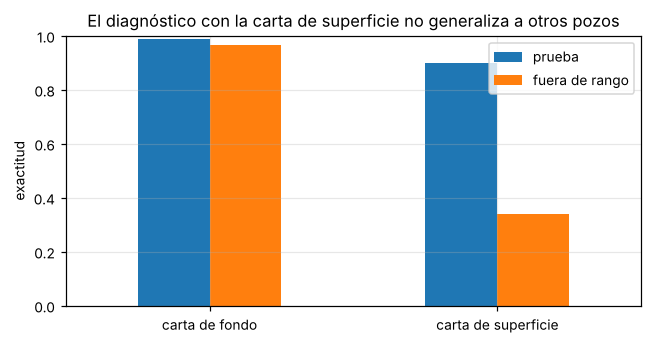

In [8]:
Xs,_=rasgos(d,'sup'); Xso,_=rasgos(o,'sup')
hgb_s=HistGradientBoostingClassifier(max_iter=250,learning_rate=0.08,max_leaf_nodes=24,l2_regularization=1.0,random_state=0).fit(Xs[itr],ytr)
comp=pd.DataFrame({'carta de fondo':[accuracy_score(yte,hgb.predict(Xte)),accuracy_score(yo,hgb.predict(Xo))],
                   'carta de superficie':[accuracy_score(yte,hgb_s.predict(Xs[ite])),accuracy_score(yo,hgb_s.predict(Xso))]},index=['prueba','fuera de rango']).round(3)
print(comp)
ax=comp.T.plot.bar(figsize=(6,3.2),rot=0); ax.set_ylabel('exactitud'); ax.set_ylim(0,1); ax.set_title('El diagnóstico con la carta de superficie no generaliza a otros pozos')
plt.tight_layout(); plt.savefig(FIG/'03_fondo_vs_superficie.png'); plt.show()

La carta de superficie depende de la dinámica de la sarta de cada pozo (profundidad, velocidad, amortiguamiento).
El modelo la aprende para los pozos que vio y **se cae con pozos distintos**. La carta de fondo, en cambio, depende
casi solo de lo que pasa en la bomba. Por eso la industria diagnostica con la carta de fondo: es la misma
conclusión de los especialistas, y aquí sale de los datos.

## 8. Explicabilidad: ¿qué mira el modelo?
Con la importancia por permutación se mide cuánto empeora el modelo si se desordena cada rasgo. Los rasgos importantes
tienen que ser los que tienen sentido físico.

rel_carreras    0.1700
min_rel         0.1184
max_rel         0.0279
forma_33        0.0268
forma_0         0.0243
forma_30        0.0157
area            0.0150
forma_31        0.0123
forma_1         0.0050
forma_34        0.0048
forma_28        0.0014
forma_62        0.0012
dtype: float64


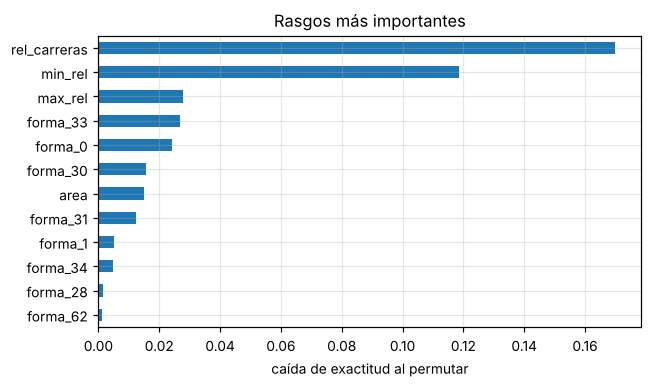

In [9]:
pi=permutation_importance(hgb,Xte,yte,n_repeats=8,random_state=0,scoring='accuracy')
imp=pd.Series(pi.importances_mean,index=NOMBRES).sort_values(ascending=False).head(12)
print(imp.round(4))
ax=imp[::-1].plot.barh(figsize=(6,3.6)); ax.set_xlabel('caída de exactitud al permutar'); ax.set_title('Rasgos más importantes'); plt.tight_layout(); plt.savefig(FIG/'04_importancia_rasgos.png'); plt.show()

## 9. ¿El modelo respeta la fenomenología?
No alcanza con que acierte en cartas "de libro": tiene que responder como la física cuando la falla aparece **de a poco**.
Se usan barridos continuos sobre un mismo pozo, que el modelo nunca vio (`datos/dataset_barrido.csv`):
- **el aporte del pozo baja de a poco**: el llenado pasa de 100 % a 35 %. La probabilidad de golpe de fluido tiene
  que pasar de ≈ 0 a ≈ 1 cuando la bomba deja de llenarse;
- **la severidad de cada fuga sube de 0 a 5**: la probabilidad de esa fuga tiene que crecer, y en 0 la carta tiene
  que ser "normal".

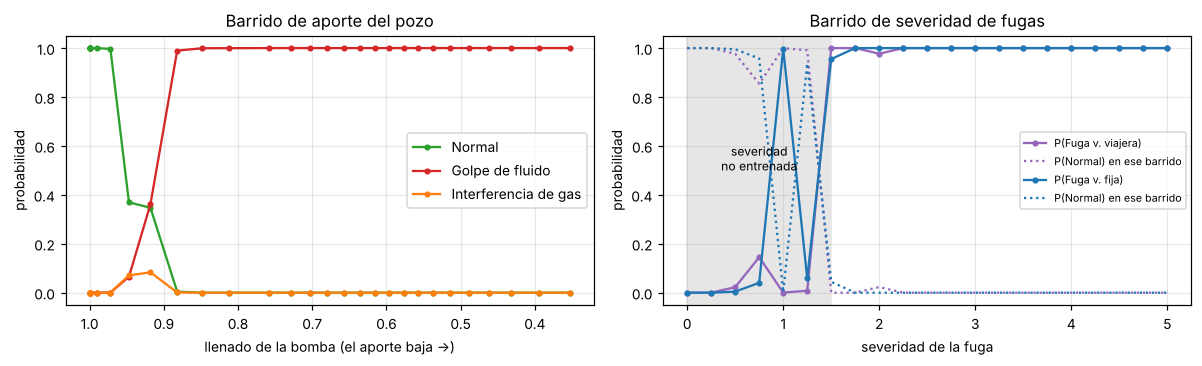

El modelo pasa a "golpe de fluido" cuando el llenado baja de 0.882
Severidad 0 → clase predicha: normal / normal
Severidad 5 → P(fuga viajera) = 1.0   P(fuga fija) = 1.0


In [10]:
b=pd.read_csv(DAT/'dataset_barrido.csv'); Xb,_=rasgos(b); Pb=hgb.predict_proba(Xb); cls=list(hgb.classes_)
ap=b[b.barrido=='aporte']; Pa=Pb[ap.index]
fig,axs=plt.subplots(1,2,figsize=(11,3.4))
for c,col in [('normal','tab:green'),('golpe_de_fluido','tab:red'),('interferencia_de_gas','tab:orange')]:
    axs[0].plot(ap.llenado,Pa[:,cls.index(c)],'o-',ms=3,color=col,label=NOMBRE[c])
axs[0].invert_xaxis(); axs[0].set_xlabel('llenado de la bomba (el aporte baja →)'); axs[0].set_ylabel('probabilidad'); axs[0].legend(); axs[0].set_title('Barrido de aporte del pozo')
for t,col in [('fuga_valvula_viajera','tab:purple'),('fuga_valvula_fija','tab:blue')]:
    fz=b[b.barrido==t]; axs[1].plot(fz.param.astype(float),Pb[fz.index,cls.index(t)],'o-',ms=3,color=col,label='P('+NOMBRE[t]+')')
    axs[1].plot(fz.param.astype(float),Pb[fz.index,cls.index('normal')],':',color=col,label='P(Normal) en ese barrido')
axs[1].axvspan(0,1.5,color='0.9',zorder=0); axs[1].text(0.75,0.5,'severidad\nno entrenada',ha='center',fontsize=8)
axs[1].set_xlabel('severidad de la fuga'); axs[1].set_ylabel('probabilidad'); axs[1].legend(fontsize=7); axs[1].set_title('Barrido de severidad de fugas')
fig.tight_layout(); fig.savefig(FIG/'05_fenomenologia_barridos.png'); plt.show()
umbral=ap.llenado[Pa[:,cls.index('golpe_de_fluido')]>0.5]
print('El modelo pasa a "golpe de fluido" cuando el llenado baja de',round(umbral.max(),3) if len(umbral) else '—')
fv=b[b.barrido=='fuga_valvula_viajera']; ff=b[b.barrido=='fuga_valvula_fija']
print('Severidad 0 → clase predicha:',hgb.predict(Xb[fv.index[:1]])[0],'/',hgb.predict(Xb[ff.index[:1]])[0])
print('Severidad 5 → P(fuga viajera) =',Pb[fv.index[-1],cls.index('fuga_valvula_viajera')].round(3),'  P(fuga fija) =',Pb[ff.index[-1],cls.index('fuga_valvula_fija')].round(3))
# chequeos: con bomba llena → normal; con llenado < 0,7 → golpe de fluido; con fuga severa → la fuga correcta
assert hgb.predict(Xb[ap.index[:1]])[0]=='normal' and (Pa[ap.llenado<0.7,cls.index('golpe_de_fluido')]>0.5).all()
assert Pb[fv.index[-1],cls.index('fuga_valvula_viajera')]>0.5 and Pb[ff.index[-1],cls.index('fuga_valvula_fija')]>0.5

La transición ocurre donde dice la física: mientras la bomba se llena, la carta es normal, y cuando el llenado
cae por debajo de ≈ 0,9 pasa a golpe de fluido. En las fugas, la probabilidad crece con la severidad. En el rango de
severidades bajas, que no se usó para entrenar, el modelo duda: es la zona donde en planta conviene revisión humana.

## 10. Exportación para el despliegue
El SCADA o el controlador de pozo tiene que ejecutar el modelo. Aquí se exporta el gradient boosting a JSON
(los árboles con sus umbrales y valores) para correrlo en el navegador, dentro del simulador. Se verifica que la
implementación propia (la misma lógica que la de JavaScript) dé **exactamente** las mismas probabilidades que scikit-learn.
En planta se usaría ONNX o el formato del sistema de control, con la misma verificación.

In [11]:
def exportar(m):
    arboles=[]
    for it in m._predictors:
        fila=[]
        for p in it:
            n=p.nodes; fila.append({'f':n['feature_idx'].tolist(),'t':[float(v) for v in n['num_threshold']],'l':n['left'].tolist(),'r':n['right'].tolist(),
                                    'h':n['is_leaf'].astype(int).tolist(),'v':[float(v) for v in n['value']]})
        arboles.append(fila)
    return {'clases':list(m.classes_),'base':np.ravel(m._baseline_prediction).tolist(),'arboles':arboles,'rasgos':NOMBRES}
modelo=exportar(hgb)
def predecir_json(mj,x):
    raw=np.array(mj['base'],float).copy()
    for fila in mj['arboles']:
        for k,a in enumerate(fila):
            i=0
            while not a['h'][i]: i=a['l'][i] if x[a['f'][i]]<=a['t'][i] else a['r'][i]
            raw[k]+=a['v'][i]
    e=np.exp(raw-raw.max()); return e/e.sum()
P_json=np.array([predecir_json(modelo,x) for x in Xte[:200]]); P_sk=hgb.predict_proba(Xte[:200])
print('Diferencia máxima entre la implementación exportada y scikit-learn:',np.abs(P_json-P_sk).max())
assert np.abs(P_json-P_sk).max()<1e-4
json.dump(modelo,open(MOD/'clasificador_cartas.json','w'),separators=(',',':'))
print('Modelo exportado:',(MOD/'clasificador_cartas.json').stat().st_size//1024,'kB ·',sum(len(f) for f in modelo['arboles']),'árboles')

Diferencia máxima entre la implementación exportada y scikit-learn: 0.0
Modelo exportado: 1601 kB · 1750 árboles


## 11. Limitaciones y próximos pasos para llevarlo a producción
1. **Validar con cartas reales.** Se necesitan cientos de cartas de fondo reales etiquetadas por ingenieros. El
   modelo sintético sirve como punto de partida (pre-entrenamiento), pero hay que medir la exactitud en datos reales.
2. **Fallas combinadas y desgaste**: barril gastado, pistón trabado, varillas con fricción en pozos desviados.
   Hay que agregar esas clases al simulador o a las etiquetas reales.
3. **Umbral de confianza**: si la probabilidad máxima es baja, la carta va a revisión humana y no genera una alerta automática.
4. **Monitoreo en operación**: comparar la distribución de los rasgos de cada mes con la del entrenamiento (deriva) y
   reentrenar cuando cambie.
5. **Modelo de forma (CNN)**: con datos reales abundantes, una red convolucional sobre la carta puede captar formas más
   sutiles. Con 2800 muestras sintéticas, el gradient boosting con rasgos físicos es más robusto y explicable.